# Pricing a lower or upper violation

Level 1. Prerequisites: elementary derivatives and Python arrays. Reading time: 20 minutes.

**Question:** How much does a scalar decision violate its interval when the upper side is priced more heavily than the lower side?


## Objectives

A soft bound is an economic decision in the optimization model. It is not a request for the solver to ignore a troublesome row after failure. We will keep the same interval and unit curvature, change only declared violation prices, and observe the resulting minimizers. The example is dimensionless, so no physical comfort or actuator claim should be attached to its numerical values.

By the end, you should distinguish a target, a bound, a violation and its penalty. The target expresses the unconstrained preference. The interval states a desired operating region. A violation measures departure from that region. Its price determines whether the optimizer purchases that departure. An optimal elastic decision may therefore lie outside the interval while satisfying the mathematical model exactly.


## Setup

Use a separate Python 3.12 environment. The native engine is a separate distribution. Install the exact environment outside the notebook:

```bash
pip install "softqp==0.1.0"
pip install "numpy==2.5.4"
pip install "scipy==1.18.1"
pip install "matplotlib==3.11.2"
pip install "osqp==1.1.3"
pip install "daqp==0.10.3"
pip install "elastiqp==0.2.0"
```

The single setup cell resolves the repository, imports the methods and prints numerical versions. No installation runs inside a kernel.


In [1]:
# Resolve inputs once so every scientific cell focuses on the optimization.
from pathlib import Path
import sys
import json
import importlib.metadata
import numpy as np
import matplotlib.pyplot as plt
from softqp.solvers import solve
candidates = [Path.cwd(), *Path.cwd().parents]
root = next(p for p in candidates if (p / "VERSION").is_file() and (p / "data-pipeline").is_dir())
sys.path.insert(0, str(root / "data-pipeline"))
from pipeline.softqp_cases import scalar, mpc
for distribution in ("softqp", "numpy", "scipy", "matplotlib", "osqp", "daqp", "elastiqp"):
    print(distribution, importlib.metadata.version(distribution))
accurate = dict(eps_abs=1e-9, eps_rel=1e-9, adaptive_rho_interval=25)
plt.rcParams.update({"figure.dpi": 100, "font.size": 10})
case_spec = json.loads((root / "docs/contracts/examples/softqp-case-spec.json").read_text(encoding="utf-8"))
case_record = json.loads((root / "data/derived/softqp/C01.json").read_text(encoding="utf-8"))


softqp 0.1.0
numpy 2.5.4
scipy 1.18.1
matplotlib 3.11.2
osqp 1.1.3
daqp 0.10.3
elastiqp 0.2.0


## Data

The authored `scalar` case generator supplies P=1, A=1 and the interval [-1,1]. The linear objective coefficient is minus the target. C01 uses target -3 and C02 uses target +3. C03 retains the positive target but changes the upper linear/quadratic prices from 0.3/2 to 1.2/4. The source is `data-pipeline/pipeline/softqp_cases.py`; no external measurements or hidden fitting are involved.

Input owner: Felipe Santibáñez-Leal. The authored generator and the scalar specification/result files are distributed under the product MIT license; see [the source and license inventory](https://github.com/fsantibanezleal/CAOS_SoftQP). `docs/contracts/examples/softqp-case-spec.json` teaches the original sparse input shape, while `data/derived/softqp/C01.json` teaches the result envelope. They contain synthetic mathematical inputs and computed outputs, not third-party operational observations.


The input diagram below separates target data from optimization output. Its horizontal interval is the desired region; the three markers are the authored targets before any penalty is applied. No measured plant is implied by their spacing. We also read the serialized scalar specification and result once, so the same small example explains the product's exchange format rather than relying on undocumented Python object fields.


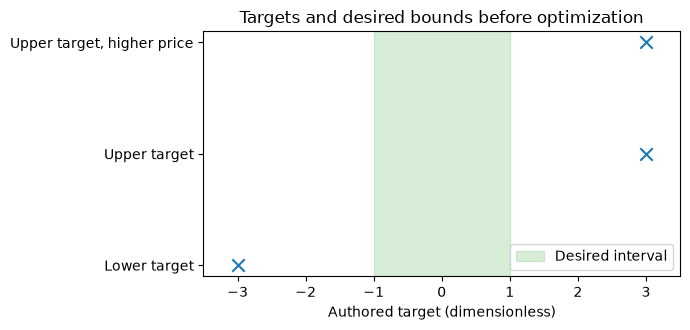

In [2]:
# Plot inputs before using any solver so the policy and data stay distinct.
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.axvspan(-1, 1, alpha=0.18, color="C2", label="Desired interval")
ax.scatter([-3, 3, 3], [0, 1, 2], marker="x", s=80, color="C0")
ax.set_yticks([0, 1, 2], ['Lower target', 'Upper target', 'Upper target, higher price'])
ax.set(xlabel='Authored target (dimensionless)',
       title='Targets and desired bounds before optimization', xlim=(-3.5, 3.5))
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()


The raw targets lie outside the shaded desired interval, with one lower-side conflict and two identical upper-side targets. The overlapping upper targets are deliberately separated vertically by policy name, so the plot does not suggest different input values. Bounds and targets share the dimensionless decision unit. The following objective plot will show what the optimizer does with these inputs after the prices are specified; neither plot is a record of observed physical behavior.


## Method

Write the original objective as $F(x)=x^2/2-tx+\phi(x)$, where the penalty is $a_l(l-x)_++a_u(x-u)_++b_l(l-x)_+^2/2+b_u(x-u)_+^2/2$. The positive-part operator prevents the unused side from charging a cost. With nonnegative coefficients, each term is convex; the unit quadratic makes this scalar objective strictly convex and its minimizer unique.

First solve the negative target with the native asymmetric-capable path. The chosen coefficients happen to be symmetric in this first case. Inspect the lower violation rather than inferring it from the sign of the objective: this objective omits the target-dependent constant, so negative objective values are entirely valid.


### The threshold and the price have different roles

The original-space convention used throughout the package is the following scalar specialization of the soft QP. Here $t$ is the unconstrained target, $l=-1$ and $u=1$ are the desired bounds, $a_l,a_u$ are linear prices, and $b_l,b_u$ are quadratic prices. All four prices are nonnegative. A violation is a distance, not the signed corrective slack used by some solver interfaces. The objective is

$$F(x)=\frac12x^2-tx+a_l(l-x)_++a_u(x-u)_++\frac{b_l}{2}(l-x)_+^2+\frac{b_u}{2}(x-u)_+^2,\qquad (v)_+=\max(v,0).$$

The source of this convention is the authored case generator together with the side-specific formulation in the product technical report. The [OSQP formulation](https://osqp.org/docs/solver/) supplies the half-quadratic objective convention. The missing constant $t^2/2$ would convert the first two terms to squared tracking error; adding it changes no minimizer. This is why a negative displayed objective is compatible with a perfectly valid optimization result.

For a positive target at or above the upper bound, the lower-side terms vanish. The derivative above the interval is $x-t+a_u+b_u(x-u)$. Setting it to zero gives a candidate, but a candidate below $u$ does not belong to that branch. Combining the branch condition with the kink at $u$ yields

$$x^*=u+\frac{(t-u-a_u)_+}{1+b_u},\qquad t\geq u.$$

For the reflected negative target the corresponding formula is $x^*=l-(l-t-a_l)_+/(1+b_l)$ when $t\leq l$. Inside the interval, neither price acts and the optimizer can equal the target. These formulas are hand-computable checks for this one-dimensional lesson; they are not a replacement implementation for coupled QPs. With $t=3$, the symmetric upper prices give $(3-1-0.3)/(1+2)=0.566667$ departure. The more expensive upper policy gives $(3-1-1.2)/(1+4)=0.160000$. The three native calls below independently produce the associated decisions.

The distinction between a linear and a quadratic price is visible in that equation. The linear price creates a threshold: if $a_u$ reaches $t-u$, this particular optimum reaches the boundary even with finite $b_u$. The quadratic price reduces departure through the denominator but alone cannot make a nonzero preferred departure vanish at a finite coefficient. A hard row instead removes all outside points from the admissible set. Calling a large quadratic price hard would confuse a useful approximation with a mathematical constraint.

The derivative also explains why one should not conclude that the expensive policy is a more accurate algorithm. Both policies are solved to the same numerical tolerance. They have different functions $F$, so they answer different economic questions. Accuracy concerns how closely a returned point minimizes its declared function; policy concerns which function was chosen. The later comparison lesson will hold the function fixed when it compares implementations.


In [3]:
# A finite price permits a lower-side trade-off instead of enforcing a hard clamp.
lower_problem = scalar(-3.0)
lower = solve(lower_problem, "asymmetric", **accurate)
print(f"Lower decision: {lower['x'][0]:.6f}")
print(f"Lower violation: {lower['metrics']['lower_violation'][0]:.6f}")


Lower decision: -1.566667
Lower violation: 0.566667


Reflecting the target while retaining symmetric prices should reflect the optimum. This is a statement about the declared objective, not a guarantee of every numerical implementation. Solving the positive case separately lets us inspect its actual output. The finite quadratic price reduces the violation continuously; it cannot generally make the desired interval a hard constraint.


In [4]:
# Reflect the target without changing either side price.
upper_problem = scalar(3.0)
upper = solve(upper_problem, "asymmetric", **accurate)
print(f"Symmetric upper decision: {upper['x'][0]:.6f}")


Symmetric upper decision: 1.566667


Now charge more for the upper side while leaving the lower side unchanged. For a point above u, differentiation gives x=(t-a_u+b_u u)/(1+b_u) whenever that expression stays above u; otherwise the kink must be considered. This branch calculation explains why changing a price changes the preferred decision. It does not compare algorithms: all three calls use the same native method.


In [5]:
# The authored asymmetric case changes costs, not bounds or curvature.
priced_problem = scalar(3.0, asymmetric=True)
priced = solve(priced_problem, "asymmetric", **accurate)
print(f"Expensive upper decision: {priced['x'][0]:.6f}")
print(f"Expensive upper violation: {priced['metrics']['upper_violation'][0]:.6f}")


Expensive upper decision: 1.160000
Expensive upper violation: 0.160000


Compare the two positive-target objectives over the same decision axis. Each curve is recomputed from the original problem evaluator, not the solver's internal cost. The vertical markers locate the returned minimizers. Looking at the complete curves reveals the changed policy more clearly than reporting only an iteration count or calling the tighter result more accurate.


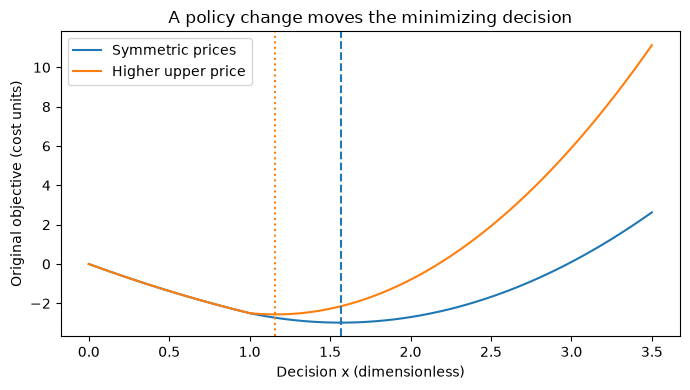

In [6]:
# Both curves retain the same target, making the side-price effect visible.
grid = np.linspace(0.0, 3.5, 250)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(grid, [upper_problem.evaluate([x])["objective"] for x in grid], label="Symmetric prices")
ax.plot(grid, [priced_problem.evaluate([x])["objective"] for x in grid], label="Higher upper price")
ax.axvline(upper["x"][0], linestyle="--", color="C0")
ax.axvline(priced["x"][0], linestyle=":", color="C1")
ax.set(xlabel="Decision x (dimensionless)", ylabel="Original objective (cost units)",
       title="A policy change moves the minimizing decision")
ax.legend()
fig.tight_layout()
plt.show()


The steeper upper-side curve attains its minimum closer to the desired boundary. Both minimizers still exceed one because neither policy makes the row hard, and both finite prices permit a trade-off with the preferred target. The curves have a shared objective convention, but their minimum values represent different optimization policies and cannot rank solver accuracy. A control engineer would choose the relative price from the meaning of the consequence before selecting a numerical algorithm.


### From one row to an exchangeable problem

The specification read above uses sparse CSC matrices: `shape` states matrix dimensions, `data` contains nonzero values, `indices` holds row indices, and `indptr` splits the columns. The vectors `q`, `lower` and `upper` refer to the original decision and row spaces. A JSON `null` bound means an absent side; it must not be converted to zero, which would invent a boundary. The `penalty` arrays retain separate `lower_linear`, `upper_linear`, `lower_quadratic` and `upper_quadratic` entries, while `soft` decides whether the row may yield at all. Their lengths must match the number of rows.

The result envelope serves a different purpose. Its `case_id` identifies the authored case; `schema_version` identifies the result shape; `rows` gives each row's id, physical `unit` and hard/soft policy. Each entry of `runs` keeps the method and its state beside the returned result. An incompatible run has a reason rather than a made-up solution vector. In a successful run, the evaluator's lower and upper departures are tied to those row ids, and the objective is reconstructed from the original problem. Thus the consumer can distinguish a changed mathematical policy from a failed numerical solve.

For new scalar data, change the target through `scalar(target, lower=..., upper=..., asymmetric=...)`, then call the same `solve` API. For unrelated engineering data, first supply meaningful matrix and row units through the sparse case specification instead of assigning a physical name to this normalized mathematical example. The named operations in `pipeline.pipeline.STAGES` are `validate`, `assemble`, `solve`, `evaluate` and `export`. Input admission decodes the sparse specification, assembly constructs the declared case, solving returns a candidate, evaluation recomputes its original objective and departures, and export retains row meaning and provenance. There is no learned feature or training step hidden inside this deterministic calculation.


## Results

**Answer:** The lower-target decision is -1.566667, while the more expensive upper-side decision is 1.160000. Their corresponding violation magnitudes are 0.566667 and 0.160000. The difference follows the asymmetric prices, not a change in interval width. The symmetric positive-target decision mirrors the negative-target result.

The closed-form branch explains these computed values under unit curvature. In a larger QP, coupled variables prevent treating each row as an independent scalar problem; the solver handles that coupling while the scalar proximal operation handles the declared interval penalty.


## Summary

Before interpreting an elastic solution, write down which side violated, its physical unit, its linear price and its quadratic price. A finite violation can be the intended optimum. Increasing a penalty is a policy intervention, whereas reducing a solver tolerance is a numerical intervention. Keeping those operations distinct will matter in the next lesson, where actuator rows stay hard while state preferences can yield.


## References

- [OSQP solver formulation](https://osqp.org/docs/solver/).
- [Schwan, Lew and Plancher, generalized slack projections](https://arxiv.org/abs/2610.35631).
- Authored scalar input and original-space evaluator in this repository and its pinned `softqp` dependency.

- [SoftQP authored scalar data and exchange specifications](https://github.com/fsantibanezleal/CAOS_SoftQP).
- [SoftQP product technical report](https://doi.org/10.5281/zenodo.23851659).
